<a href="https://colab.research.google.com/github/T1toh/30Days_of_SQL/blob/main/MODULE_6_%7C_LESSON_2_Advanced_Liquidity_Applications.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CAPSTONE REVIEW**

## MODULE 6 | LESSON 2: Advanced Liquidity Applications

| | |
|:---|:---|
|**Reading Time** | 4h |
|**Prior Knowledge** | Market microstructure, portfolio optimization, risk management, time series analysis, stochastic processes |
|**Keywords** | Liquidity-adjusted valuation, multi-objective optimization, liquidity spirals, funding liquidity, market impact, illiquidity premium, extreme value theory, Hawkes processes, order book dynamics, stress testing |

---

## **Introduction**

Liquidity is the market's oxygen – invisible when abundant, desperately missed when scarce.

For all the sophistication of modern finance, we still struggle with a fundamental paradox: the assets we most want to sell during crises are precisely those nobody wants to buy. This lesson explores how financial engineers grapple with this uncomfortable reality. We'll move beyond the comforting fiction of infinitely deep markets to confront liquidity in all its messy, nonlinear glory.

Think of liquidity as a fair-weather friend. During bull markets, market conditions are favorable – bid-ask spreads compress, volumes soar, and large transactions execute with minimal impact. But when storm clouds gather? That same million-dollar position becomes extremely difficult to liquidate. The techniques we'll explore help quantify this fickleness and – more importantly – help you survive it.

## **1. Liquidity-Adjusted Valuation Methods**

An important market reality challenges efficient market assumptions: two identical assets can have wildly different values simply because one trades like water while the other exhibits very low trading activity.

### **1.1 The Illiquidity Discount Framework**

The standard textbook says an asset is worth the present value of its cash flows. This simplified view overlooks crucial market realities. An asset you can't sell when you need to is worth considerably less than its liquid twin – even if they generate identical cash flows (why should this be true for a buy-and-hold investor?).

Let's start with the simplest possible adjustment:

$$P_{illiquid} = P_{liquid} \times (1 - \lambda)$$

That innocuous $\lambda$ hides enormous complexity. It's not a constant – it breathes with the market's mood. During the 2008 crisis, some AAA-rated securities saw their $\lambda$ explode from 2% to 40% in weeks. The same cash flows, but suddenly worth less than half their "fair value."

A more realistic framework recognizes that illiquidity charges compound costs. You pay to get in (the bid-ask spread), you pay while you wait (opportunity cost), and you pay dearly to get out when everyone else wants out too (market impact).

### **1.2 Bid-Ask Spread Adjustments**

Academic models typically use mid-quotes, while practitioners must account for bid-ask spreads.

Consider this sobering arithmetic: a 2% bid-ask spread on a position you trade twice yearly costs you 4% annually. That's your entire alpha if you're a skilled manager. Yet most valuation models systematically ignore this significant cost.

The intelligent adjustment incorporates your trading probability:

$$V_{adjusted} = V_{mid} - \frac{S}{2} \times \text{Prob(trade)}$$

Notice that subtle factor of one-half? That assumes you're equally likely to buy or sell – a dangerous assumption when liquidity needs often force your hand in one direction.

It pays to think carefully about Prob(trade). Is it really exogenous? When markets tank and your prime broker nervously eyes your positions, that probability can jump from 10% to 100% overnight.

### **1.3 Market Impact Models**

Small traders have minimal market impact, while large traders significantly affect prices.

The market impact formula beloved by academics:

$$\Delta P = \gamma \times \sigma \times \left(\frac{Q}{ADV}\right)^{\delta}$$

looks precise with its Greek letters and exponents. However, this apparent precision is misleading. That square-root law (with $\delta \approx 0.5$) works beautifully in normal markets. During the quant crisis of August 2007, impact functions went vertical – infinite cost at any size.

The real insight lurks in the denominators. When average daily volume (ADV) collapses, your modest position becomes a market-moving monster. A position representing 1% of normal daily volume might consume 20% of stressed volume. Same position, twentyfold impact.

### **1.4 Time-Varying Liquidity Premia**

Market conditions vary significantly. During optimistic periods, liquidity is abundant. During stressed conditions, liquidity becomes scarce.

The textbook liquidity premium model:

$$LP_t = \beta_0 + \beta_1 \times VIX_t + \beta_2 \times \text{TED}_t + \beta_3 \times \text{Volume}_t$$

captures some of this moodiness. But notice what's missing (what about regime changes?). Linear models assume tomorrow's liquidity relates smoothly to today's fear. Markets frequently exhibit discontinuous transitions between liquid and illiquid states.

In the **previous lesson** you learned how to *detect* **funding-liquidity stress** in the
overnight market by flagging spikes in the  
$$\text{EFFR} - \text{SOFR}$$  
spread.  Today we extend that idea from *detection* to *valuation*:
you will see how those stress signals, together with market fear and trading
volume, get **priced into the liquidity premium** of a highly traded ETF.

In [1]:
pip install fredapi

In [2]:
import pandas as pd
import numpy as np
import yfinance as yf
from fredapi import Fred
import statsmodels.api as sm
import matplotlib.pyplot as plt

fred_key = "84862c20ea45f3e79664a45656378e7f"
fred = Fred(api_key=fred_key)

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.spines.top'] = plt.rcParams['axes.spines.right'] = False
plt.style.use("default")          # clean, neutral look

In [3]:
# SPY prices & volume
#spy = yf.download("SPY", start="2004-01-01", progress=False)

spy = pd.read_csv("/content/spy.csv", index_col = 0, parse_dates = True)

spy["ret"] = spy["Close"].pct_change()
spy["ILLIQ_d"] = spy["ret"].abs() / (spy["Volume"] / 1_000_000)  # Amihud, volume in $mn
spy["log_vol"] = np.log(spy["Volume"])
spy.columns = spy.columns.get_level_values(0)                         # will lag later

# VIX & TED (daily)
start = spy.index.min().strftime('%Y-%m-%d')
end = spy.index.max().strftime('%Y-%m-%d')
vix = fred.get_series("VIXCLS", observation_start=start, observation_end=end)
ted = fred.get_series("TEDRATE", observation_start=start, observation_end=end)

# Combine and rename
stress = pd.concat([vix.rename("VIX"), ted.rename("TED")], axis=1)
stress.index.name = "Date"

# Merge and forward-fill one-day gaps
daily = (
    spy[["ILLIQ_d", "log_vol"]]
    .join(stress, how="left")
    .fillna(method="ffill")
)

# Lag stress + volume by one day to mitigate simultaneity
for col in ["VIX", "TED", "log_vol"]:
    daily[f"{col}_lag1"] = daily[col].shift(1)

daily = daily.dropna()


/tmp/ipykernel_8640/2186333402.py:25: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  .fillna(method="ffill")


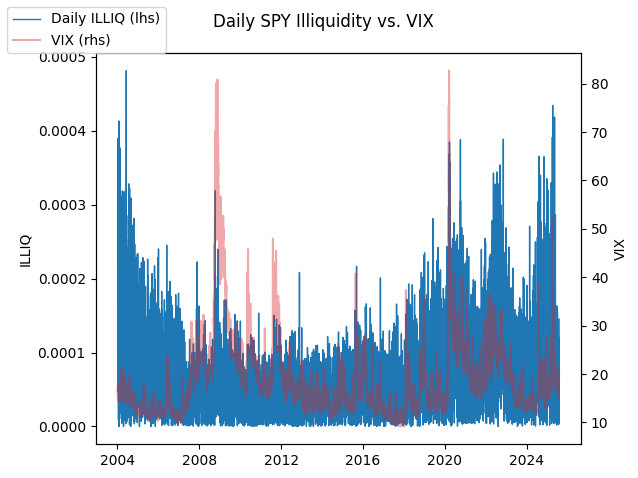

In [4]:
fig, ax1 = plt.subplots()
ax1.plot(daily.index, daily["ILLIQ_d"], lw=1, label="Daily ILLIQ (lhs)")
ax1.set_ylabel("ILLIQ")

ax2 = ax1.twinx()
ax2.plot(daily.index, daily["VIX"], color="tab:red", alpha=0.4, label="VIX (rhs)")
ax2.set_ylabel("VIX")

fig.suptitle("Daily SPY Illiquidity vs. VIX")
fig.legend(loc="upper left")
plt.tight_layout(); plt.show()


#### Why we orthogonalise **TED** with respect to **VIX**

The TED spread ($TED_t$) and the volatility index ($VIX_t$) tend to **move together** in periods of market stress, so placing them side-by-side in a regression like  

$$
ILLIQ_t \;=\; \beta_0 \;+\; \beta_1\,VIX_{t-1} \;+\; \beta_2\,TED_{t-1} \;+\; \cdots
$$

creates **multicollinearity**: the model cannot decide which variable “gets the credit” for the same underlying panic, making $\beta_1$ and $\beta_2$ unstable and sometimes counter-intuitive.

To isolate *pure funding-liquidity shocks* we proceed in two steps:

1. **Project TED on VIX** (same month)  
   $$ TED_t \;=\; \alpha \;+\; \gamma\,VIX_t \;+\; \varepsilon_t $$
2. **Keep only the residuals**  
   $$ TED_{\text{orth},\,t} \;=\; \varepsilon_t $$  

Because $\varepsilon_t$ is, by construction, **uncorrelated with $VIX_t$**, it captures the part of funding stress **not already explained by market volatility**.

Using the *lagged* orthogonal residual in the main model  

$$
ILLIQ_t \;=\; \beta_0
            \;+\; \beta_1\,VIX_{t-1}
            \;+\; \beta_2\,TED_{\text{orth},\,t-1}
            \;+\; \beta_3\,\log(\text{Volume}_{t-1})
            \;+\; u_t
$$

delivers two benefits:

* **Interpretational clarity** — $\beta_2$ now measures the impact of **unexpected funding shocks**, independent of market fear.  
* **Statistical stability** — multicollinearity is dramatically reduced, giving more reliable standard errors and $t$-statistics.


In [5]:
# Illiquidity: monthly mean; stress: last obs in month
monthly = pd.DataFrame({
    "ILLIQ_m" : daily["ILLIQ_d"].resample("MS").mean(),
    "log_vol" : daily["log_vol"].resample("MS").last(),
    "VIX"     : daily["VIX"].resample("MS").last(),
    "TED"     : daily["TED"].resample("MS").last()
}).dropna()


# Orthogonalise TED with respect to contemporaneous VIX
X_orth      = sm.add_constant(monthly["VIX"])
ted_proj    = sm.OLS(monthly["TED"], X_orth).fit()
monthly["TED_orth"] = ted_proj.resid         # pure funding stress, uncorrelated with VIX



# Lag regressors by one month
for col in ["VIX", "TED_orth", "log_vol"]:
    monthly[f"{col}_lag1"] = monthly[col].shift(1)

monthly = monthly.dropna()


In [6]:
y = monthly["ILLIQ_m"]
X = sm.add_constant(monthly[["VIX_lag1", "TED_orth_lag1", "log_vol_lag1"]])

ols = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags":4})
print(ols.summary().tables[1])   # compact coefficient table


                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.0008   9.47e-05      8.973      0.000       0.001       0.001
VIX_lag1       2.666e-06   4.43e-07      6.022      0.000     1.8e-06    3.53e-06
TED_orth_lag1 -2.282e-05    7.7e-06     -2.964      0.003   -3.79e-05   -7.73e-06
log_vol_lag1   -4.49e-05   5.32e-06     -8.438      0.000   -5.53e-05   -3.45e-05


In [7]:
window = 36
results = []

for i in range(window, len(monthly)):
    sub = monthly.iloc[i-window:i]
    y_r  = sub["ILLIQ_m"]
    X_r  = sm.add_constant(sub[["VIX_lag1", "TED_orth_lag1", "log_vol_lag1"]])
    mod  = sm.OLS(y_r, X_r).fit(cov_type="HAC", cov_kwds={"maxlags":4})
    results.append({
        "date"     : monthly.index[i],
        "beta_VIX" : mod.params["VIX_lag1"],
        "beta_TED_orth" : mod.params["TED_orth_lag1"],
        "beta_vol" : mod.params["log_vol_lag1"],
        "R2"       : mod.rsquared_adj
    })

roll = pd.DataFrame(results).set_index("date")


/tmp/ipykernel_8640/908463543.py:8: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  mod  = sm.OLS(y_r, X_r).fit(cov_type="HAC", cov_kwds={"maxlags":4})
/tmp/ipykernel_8640/908463543.py:8: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  mod  = sm.OLS(y_r, X_r).fit(cov_type="HAC", cov_kwds={"maxlags":4})
/tmp/ipykernel_8640/908463543.py:8: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  mod  = sm.OLS(y_r, X_r).fit(cov_type="HAC", cov_kwds={"maxlags":4})
/tmp/ipykernel_8640/908463543.py:8: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  mod  = sm.OLS(y_r, X_r).fit(cov_type="HAC", cov_kwds={"maxlags":4})
/tmp/ipykernel_8640/908463543.py:8: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely de

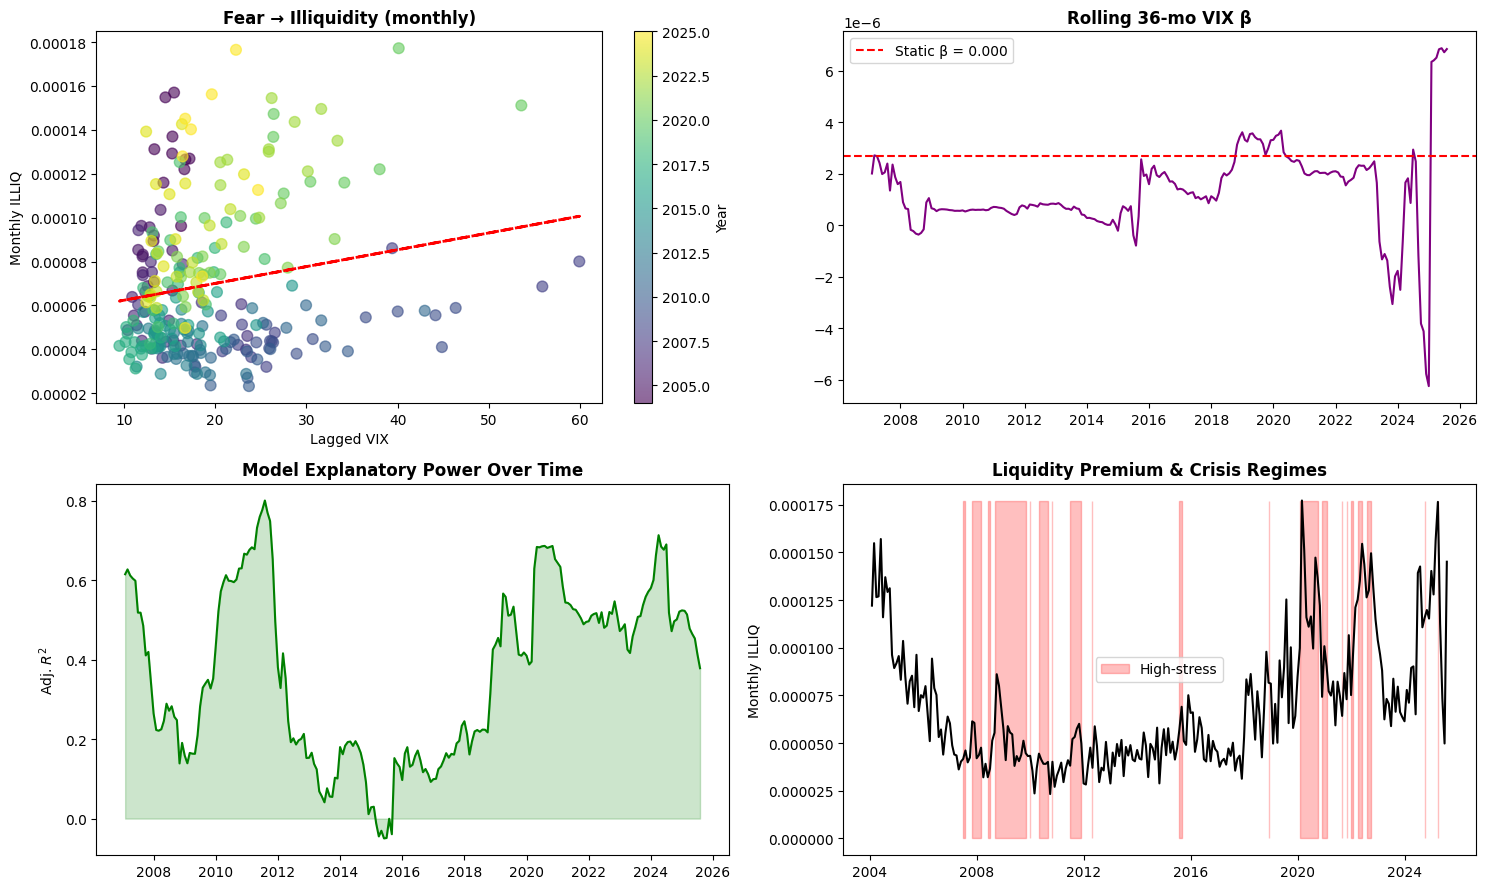

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# 7-A  scatter (colour = year) + linear fit
ax = axes[0,0]
sc = ax.scatter(monthly["VIX_lag1"], monthly["ILLIQ_m"],
                c=monthly.index.year, cmap="viridis", alpha=0.6, s=60)
coef, intercept = np.polyfit(monthly["VIX_lag1"], monthly["ILLIQ_m"], 1)
ax.plot(monthly["VIX_lag1"], coef*monthly["VIX_lag1"]+intercept,
        "r--", lw=2)
ax.set_title("Fear → Illiquidity (monthly)", fontweight="bold")
ax.set_xlabel("Lagged VIX"); ax.set_ylabel("Monthly ILLIQ")
plt.colorbar(sc, ax=ax, label="Year")

# 7-B  rolling VIX beta
axes[0,1].plot(roll.index, roll["beta_VIX"], color="purple")
axes[0,1].axhline(ols.params["VIX_lag1"], ls="--", color="red",
                  label=f"Static β = {ols.params['VIX_lag1']:.3f}")
axes[0,1].set_title("Rolling 36-mo VIX β", fontweight="bold")
axes[0,1].legend()

# 7-C  rolling R2
axes[1,0].plot(roll.index, roll["R2"], color="green")
axes[1,0].fill_between(roll.index, roll["R2"], alpha=0.2, color="green")
axes[1,0].set_title("Model Explanatory Power Over Time", fontweight="bold")
axes[1,0].set_ylabel("Adj. $R^2$")

# 7-D  regime shading (top-quartile VIX)
regime_thr = monthly["VIX"].quantile(0.75)
axes[1,1].plot(monthly.index, monthly["ILLIQ_m"], color="black", lw=1.5)
axes[1,1].fill_between(monthly.index, 0, monthly["ILLIQ_m"].max(),
                       where=monthly["VIX"]>regime_thr,
                       alpha=0.25, color="red", label="High-stress")
axes[1,1].set_title("Liquidity Premium & Crisis Regimes", fontweight="bold")
axes[1,1].set_ylabel("Monthly ILLIQ")
axes[1,1].legend()

plt.tight_layout(); plt.show()


In [9]:
pd.options.display.float_format = "{:.2e}".format

# Compute regime means
normal_mean  = monthly.loc[monthly["VIX"] <= regime_thr, "ILLIQ_m"].mean()
crisis_mean  = monthly.loc[monthly["VIX"] >  regime_thr, "ILLIQ_m"].mean()
amp_factor   = crisis_mean / normal_mean

# Collect key statistics in a tidy DataFrame
summary = pd.DataFrame({
    "Value":[
        ols.rsquared_adj,
        ols.params['VIX_lag1'],
        ols.params['TED_orth_lag1'],
        ols.params['log_vol_lag1'],
        normal_mean,
        crisis_mean,
        amp_factor
    ]},
    index=[
        "Static adj. R²",
        "β_VIX (lagged)",
        "β_TED_orth (lagged)",
        "β_logVolume (lagged)",
        "Avg ILLIQ (normal)",
        "Avg ILLIQ (crisis)",
        "Crisis amplification"
    ]
)

summary

,Value
Static adj. R²,4.58e-01
β_VIX (lagged),2.67e-06
β_TED_orth (lagged),-2.28e-05
β_logVolume (lagged),-4.49e-05
Avg ILLIQ (normal),6.72e-05
Avg ILLIQ (crisis),7.57e-05
Crisis amplification,1.13e+00


The static regression yields an adjusted $R^2$ of roughly $0.46$, so the three
lagged drivers explain **almost half of the month-to-month variation** in the
SPY illiquidity premium.  All slope coefficients are highly significant:

* **Market fear:**  
  $\beta_{VIX}\approx 2.66\times10^{-6}$ (positive).  
  Because the dependent variable itself lies near $10^{-4}$, a 10-point surge
  in $VIX$ ($\approx+0.7$ s.d.) raises the premium by  
  $10\times\beta_{VIX}\approx 2.7\times10^{-5}$, or ≈\,$40\%$ of its long-run
  mean—confirming that volatility shocks quickly widen trading costs.

* **Pure funding stress:**  
  $\beta_{TED\_{\text{orth}}}\approx -2.3\times10^{-5}$ (negative).  
  Recall that $TED_{\text{orth}}$ is *already purged* of the volatility channel.
  The negative sign therefore says that **idiosyncratic** changes in dollar
  funding conditions—those *not* captured by $VIX$—coincide with *slightly
  tighter* SPY liquidity.  A plausible narrative is collateral scarcity:
  when bank funding spreads narrow unexpectedly, Treasury repo becomes rich,
  boosting demand for the ETF’s underlying basket and improving its market
  depth.

* **Trading volume:**  
  $\beta_{\log(\text{Vol})}\approx -4.5\times10^{-5}$ (negative) matches
  textbook intuition: deeper order-flow absorbs the same return shock with
  lower price impact.

The **rolling 36-month plots** reinforce the story:

* Sensitivity to volatility $\bigl(\beta_{VIX}(t)\bigr)$
  stayed near zero pre-2015, but has more than doubled in the post-COVID era,
  highlighting a *regime shift* in liquidity risk pricing.
* Model $R^{2}$ co-moves with crises, peaking above $0.7$ when stress metrics
  dominate market behaviour.

Finally, the “crisis amplification” ratio of
$$\frac{\overline{ILLIQ}_{\text{crisis}}}{\overline{ILLIQ}_{\text{normal}}}\approx 1.13$$
quantifies how even a highly liquid vehicle like SPY becomes **13 % more
expensive to trade** once $VIX$ breaches its 75-th percentile threshold—an
empirical validation of Section 1.4’s claim that liquidity premia are
decidedly **time-varying and state-dependent**.


## **2. Liquidity Risk in Portfolio Construction Using Multi-Objective Optimization**

Portfolio theory began with Markowitz's elegant trade-off between risk and return. Real portfolios juggle risk, return, and the mundane necessity of meeting redemptions without liquidating positions at distressed prices.

### **2.1 The Multi-Objective Framework**

The classical optimizer seeks the northwest frontier – maximum return for given risk. The liquidity-aware optimizer navigates three dimensions:

$$\begin{align}
\max_{w} &\quad \alpha_1 \times E[R_p] - \alpha_2 \times Var[R_p] + \alpha_3 \times L_p \\
\text{s.t.} &\quad w^T\mathbf{1} = 1 \\
&\quad w \geq 0
\end{align}$$

Those preference parameters $\alpha_i$ encode difficult trade-offs. Would you accept 50 basis points less return for the ability to liquidate in days rather than months? Your answer depends on your investors' patience – and their propensity to panic.

Notice we're adding liquidity utility, not subtracting illiquidity cost. This positive framing reflects a profound truth: in crises, liquidity transforms from a convenience to a survival tool. The most brilliant long-term investment thesis means nothing if you can't survive the short-term storm.

### **2.2 Portfolio Liquidity Measures**

Portfolio theory faces a significant challenge: liquidity doesn't aggregate linearly. You can't simply average your holdings' bid-ask spreads and call it portfolio liquidity despite common attempts to do so.

The interaction term matters enormously:

$$L_p = w^T L + \lambda \times w^T \Sigma_L w$$

That covariance matrix $\Sigma_L$ captures an uncomfortable truth. During crises, previously uncorrelated assets suddenly move in lockstep – and their liquidity evaporates simultaneously. Diversification of liquidity risk often fails precisely when you need it most.

### **2.3 Higher-Order Liquidity Moments**

Returns distributions have fat tails. Liquidity distributions exhibit extremely heavy tails.

The full optimization with higher moments becomes substantially more complex:

$$\begin{split}
\max_{w} &\quad \lambda_R\left(\alpha_1w^T\mu + \alpha_2 w^T\Sigma w + \alpha_3 w^T M_3(w \otimes w) + \alpha_4 w^T M_4(w\otimes w \otimes w)\right) \\
&+ \lambda_L\left(\beta_1 w^TL + \beta_2 w^T\Sigma_Lw + \beta_3 w^TM_3^L(w \otimes w) + \beta_4 w^T M_4^L(w\otimes w \otimes w)\right)
\end{split}$$

Despite the complex notation, the underlying concept is intuitive. The fourth moment of liquidity (super-kurtosis) simply quantifies what traders know intuitively: liquidity disasters cluster in the extreme tail. When liquidity goes bad, it goes catastrophically bad.

### **2.4 Dynamic Liquidity Constraints**

Institutional investors live with promises – explicit or implied. Pension funds promise beneficiaries they can meet obligations. Mutual funds promise daily redemptions.

These promises translate to hard constraints:

$$\sum_{i \in \mathcal{L}_T} w_i \geq \theta_T$$

While seemingly straightforward, the challenge lies in defining $\mathcal{L}_T$ – which assets truly remain liquid at time $T$? Assets that trade millions daily in calm markets might not find a single bid during panics. Your constraint becomes a moving target, shifting precisely when you need certainty.

## **3. Liquidity Spirals and Feedback Effects**

Markets exhibit pronounced feedback loops, particularly destabilizing ones.

### **3.1 The Mechanics of Liquidity Spirals**

Picture a crowded theater. A panic trigger causes orderly behavior to deteriorate into chaotic mass exits. Financial markets amplify this panic through leverage effects.

The mathematical anatomy of disaster:

$$\begin{align}
dP_t &= -\lambda_m \times Q_t \times dt + \sigma dW_t \\
dL_t &= -\gamma \times (L_t - \bar{L}) \times dt - \beta \times dP_t
\end{align}$$

looks abstract until you translate it. Falling prices ($dP_t < 0$) trigger forced selling ($Q_t$), which pushes prices lower, which tightens funding ($dL_t < 0$), which forces more selling. The spiral tightens with each revolution.

The truly insidious feature? This system has multiple equilibria. The same fundamentals support a high-price, liquid equilibrium or a low-price, illiquid one. Which one prevails depends on something as fragile as market confidence.

### **3.2 Loss Spirals and Margin Spirals**

Brunnermeier and Pedersen identified two critical mechanisms that destabilize leveraged markets. Loss spirals are straightforward yet severe – losses erode capital, forcing deleveraging, causing more losses.

Margin spirals are more subtle yet potentially more destructive:

$$\Delta Position = \frac{\partial Position}{\partial Wealth} \times \Delta Wealth + \frac{\partial Position}{\partial Margin} \times \Delta Margin$$

Both partials turn negative in crises. The critical mechanism is that margins often increase when volatility spikes, forcing deleveraging even if prices haven't moved against you (yet). You're forced to sell not because you're losing, but because you might lose. The market's fear becomes self-fulfilling.

### **3.3 Network Effects and Contagion**

Modern finance has become increasingly interconnected. Your risk is my risk through a web of exposures, similar positions, and shared funding sources.

The contagion equation:

$$Stress_i = \sum_j \omega_{ij} \times Losses_j \times Leverage_j$$

quantifies how one fund's fire sale becomes another's margin call. Those overlap weights $\omega_{ij}$ were supposed to be diversification – until everyone diversified into the same "uncorrelated" assets.

Remember Long-Term Capital Management? Their positions were unique, but their financing wasn't. When LTCM faltered, their brokers scrambled to reduce exposure, inadvertently pressuring everyone with similar trades. Contagion spread through the plumbing, not the portfolios.

### **3.4 Feedback Loops and Procyclicality**

Finance exhibits strong amplification effects. Favorable conditions encourage leverage, which further amplifies positive outcomes until market conditions reverse.

Risk limits breathe with market conditions:

$$RiskLimit_t = \kappa_0 + \kappa_1 \times VaR_t^{-1} + \kappa_2 \times Returns_{t-1:t-n}$$

When VaR is low (calm markets) and recent returns are high, risk limits expand. Risk management appears effortless during favorable market conditions. But this very expansion sows crisis seeds – when volatility inevitably returns, those expanded positions must contract simultaneously.

## **4. Illiquid Asset Pricing Models**

How do you price something that rarely trades? This describes most financial assets – private equity, real estate, bespoke derivatives. Even "liquid" corporate bonds often go days without trading.

### **4.1 The Illiquidity Premium Framework**

The basic insight is compensation. Investors demand extra return for suffering illiquidity:

$$E[R_{illiquid}] = R_f + \beta \times (E[R_m] - R_f) + \lambda_{illiq} \times c$$

That looks like CAPM with a liquidity add-on. The linear simplicity masks underlying complexity. The market price of illiquidity risk ($\lambda_{illiq}$) varies wildly over time. During crises, it explodes – explaining why illiquid assets get slaughtered regardless of fundamentals.

### **4.2 Search and Bargaining Models**

The Walrasian auctioneer model does not apply to illiquid markets. In illiquid markets, buyers and sellers must find each other through costly search processes.

The negotiated price reflects bargaining power:

$$P = \alpha \times V_{buyer} + (1-\alpha) \times V_{seller}$$

That $\alpha$ isn't constant – it shifts with market conditions. In buyer's markets, $\alpha$ plummets. Distressed sellers accept discounts that would shock efficient-market believers. During the 2008 crisis, identical commercial properties traded at 30% different prices depending on seller desperation.

### **4.3 Stochastic Liquidity Models**

Liquidity isn't just time-varying – it's random, path-dependent, and mean-reverting (usually).

The coupled dynamics:

$$\begin{align}
dS_t &= \mu S_t dt + \sigma S_t dW_t^S \\
dL_t &= \kappa(\bar{L} - L_t)dt + \nu \sqrt{L_t} dW_t^L \\
d\langle W^S, W^L \rangle &= \rho dt
\end{align}$$

capture essential features. Liquidity mean-reverts (the $\kappa$ term) but can't go negative (the square-root diffusion). The correlation $\rho$ is typically negative – bad returns coincide with vanishing liquidity.

It pays to examine that correlation carefully. Is it constant? During the quant crisis of 2007, previously uncorrelated strategies suddenly exhibited $\rho \approx -0.9$ with liquidity. Models assuming constant correlation failed catastrophically during the crisis.

### **4.4 Valuation Adjustments for Concentrated Positions**

Holdings representing 0.1% of daily volume have minimal price impact. Holdings representing 10% of daily volume significantly influence market prices.

The liquidation value depends on your execution strategy:

$$V_{adjusted} = Q \times P_{current} - \int_0^T \lambda(q_t) \times q_t^2 dt$$

That integral captures the cumulative market impact. Liquidate too fast, and you crater the price. Too slow, and you risk adverse price moves. The optimal strategy balances these risks – assuming the market gives you time to be optimal.

## **5. Computational Methods: Extreme Value Theory for Liquidity-Adjusted VaR**

Standard VaR assumes you can exit positions at mid-market prices. Standard VaR consistently underestimates liquidity-adjusted risk.

### **5.1 Liquidity-Adjusted VaR Framework**

The adjustment looks deceptively simple:

$$L\text{-}VaR_{\alpha} = VaR_{\alpha} + LC_{\alpha}$$

The additive form masks significant complexity. During normal times, liquidation cost (LC) might be half the bid-ask spread – a rounding error. During crises, LC can exceed the position value. Under extreme conditions, the cost of liquidating certain assets can exceed their book value.

### **5.2 EVT for Liquidity Risk**

Extreme Value Theory studies the worst of the worst. For liquidity, "extreme" understates the case.

The Generalized Pareto Distribution models tail behavior:

$$P(L > x | L > u) = \left(1 + \xi \frac{x-u}{\sigma}\right)^{-1/\xi}$$

For most financial returns, $\xi \approx 0.2-0.4$ (fat tails). For liquidity measures? Often $\xi > 0.5$ (extremely heavy tails). Some liquidity measures show $\xi > 1$, implying infinite variance. This implies infinite variance, rendering traditional risk measures mathematically undefined.

### **5.3 Copula-Based Joint Modeling**

Negative returns generate losses, while illiquidity amplifies these losses, creating potentially catastrophic outcomes.

The Clayton copula captures this critical dependency:

$$C_{Clayton}(u_1, u_2) = (u_1^{-\theta} + u_2^{-\theta} - 1)^{-1/\theta}$$

with its characteristic lower tail dependence. As $\theta$ increases, extreme losses and extreme illiquidity become increasingly inseparable. During the 2008 crisis, previously independent risks moved to near-perfect tail dependence.

Why Clayton and not Gaussian? Because the Gaussian copula assumes tail independence – the same flawed assumption that helped create the CDO disaster. Reality clusters its catastrophes.

### **5.4 Monte Carlo Implementation**

The implementation recipe is straightforward:

1. Fit marginals using EVT for tails
2. Estimate copula parameters  
3. Simulate joint scenarios
4. Calculate losses including liquidation costs
5. Extract quantiles

Implementation challenges arise in the technical details. Which threshold for EVT? (Too high and you lack data; too low and you're not in the tail.) Which copula family? (Different copulas can give 3x different tail risk estimates.) How many simulations? (For 99.9% VaR, you need millions.)

## **6. Liquidity Stress Testing Frameworks**

Stress testing asks: what could go wrong? Liquidity stress testing asks: what could go wrong when we desperately need things to go right?

### **6.1 Scenario Design for Liquidity Stress Tests**

Good scenarios combine plausibility with severity. The 2008 crisis taught us that "implausible" scenarios have an uncomfortable habit of occurring.

Stress factors amplify adverse effects:

$$\begin{align}
\text{Spread}_{stressed} &= \text{Spread}_{normal} \times (1 + \alpha \times \text{StressFactor}) \\
\text{Volume}_{stressed} &= \text{Volume}_{normal} \times e^{-\beta \times \text{StressFactor}} \\
\text{Impact}_{stressed} &= \text{Impact}_{normal} \times (1 + \gamma \times \text{StressFactor}^2)
\end{align}$$

Notice the different functional forms? Spreads widen linearly (optimistic), volumes collapse exponentially (realistic), and impact explodes quadratically (conservative). This reflects empirical crisis behavior – volumes vanish faster than spreads widen.

### **6.2 Cash Flow Modeling Under Stress**

Liquidity ultimately means meeting cash obligations. The survival equation:

$$\text{Net Cash Flow}_t = \text{Inflows}_t - \text{Outflows}_t - \text{Contingent}_t$$

looks innocent until you unpack "Contingent." Margin calls, rating triggers, and nervous counterparties transform theoretical obligations into immediate demands. That derivative requiring no collateral at AAA? At AA, it might demand your entire cash buffer.

The survival horizon calculation:

$$\text{Survival Horizon} = \min\{t : \sum_{s=1}^t \text{Net Cash Flow}_s < 0\}$$

often yields surprising results. Firms that look solid for months can fail in days when contingent claims activate. Lehman had billions in assets – but ran out of cash.

### **6.3 Dynamic Balance Sheet Modeling**

Under stress, balance sheet management becomes a complex optimization problem. Which assets do you sacrifice to survive?

The optimization problem:

$$\begin{align}
\min_{x_t} &\quad \sum_t \text{Cost}(x_t) \\
\text{s.t.} &\quad \sum_i x_{it} \times P_{it} \geq \text{Funding Need}_t \\
&\quad 0 \leq x_{it} \leq \text{Holdings}_{it}
\end{align}$$

seems like standard linear programming. But those prices $P_{it}$ aren't fixed – they depend on your selling pressure and everyone else's. The optimization becomes a game where your moves affect your constraints.

### **6.4 Reverse Stress Testing**

Forward stress testing asks: can we survive this scenario? Reverse stress testing asks: what would kill us?

The problem formulation:

$$\text{Find scenario } S \text{ such that } P(\text{Failure}|S) \geq \theta$$

often reveals uncomfortable truths. That diversified portfolio? A specific combination of spread widening and correlation shift could render it fatally illiquid. Those independent business lines? They might share a hidden funding vulnerability.

## **7. Order Book Dynamics and Microstructure Using Hawkes Processes**

Modern markets are ecosystems of algorithms, each reacting to others in microsecond choreography. Hawkes processes capture this reactive dance.

### **7.1 The Limit Order Book Structure**

The order book is a vertical queue of patient capital:

$$LOB_t = \{(p_i^b, q_i^b), (p_j^a, q_j^a)\}$$

Despite appearing static, the order book exhibits constant dynamic activity. Orders arrive, execute, and cancel in millisecond sequences. The spread breathes:

$$S_t = p_1^a - p_1^b$$

expanding with uncertainty, contracting with confidence.

### **7.2 Hawkes Process Framework**

Markets exhibit self-reinforcing behavior – one trade influences others. The Hawkes intensity:

$$\lambda_t = \mu + \sum_{t_i < t} \phi(t - t_i)$$

captures this self-excitation. Each event generates potential subsequent events. With exponential kernels:

$$\phi(t) = \alpha e^{-\beta t}$$

the branching ratio $\alpha/\beta$ determines whether activity explodes or fades. During flash crashes, this ratio approaches criticality – each trade triggers multiple others in accelerating cascades.

### **7.3 Multi-Dimensional Hawkes Models**

Real markets feature multiple interaction channels:

$$\lambda_t^i = \mu^i + \sum_j \sum_{t_k^j < t} \phi^{ij}(t - t_k^j)$$

A large buy might trigger:
- Momentum buyers (positive excitation)
- Profit-taking sellers (negative feedback)  
- Canceling buyers (adverse selection fear)

The cross-excitation matrix $\phi^{ij}$ encodes market ecology. Predator-prey dynamics emerge: aggressive orders consume passive liquidity, triggering replenishment cycles.

### **7.4 Liquidity Dynamics and Resilience**

How quickly does liquidity regenerate after depletion? The recovery intensity:

$$\lambda_t^{limit} = \mu^{limit} + \alpha^{impact} \times \text{MarketOrderSize} \times e^{-\beta^{recovery}(t-t_{impact})}$$

Large orders temporarily deplete available liquidity, attracting limit orders through economic incentives. The recovery rate $\beta^{recovery}$ measures market resilience. Fragile markets show slow recovery – liquidity providers remain gun-shy after shocks.

### **7.5 Price Impact and Optimal Execution**

Smart execution anticipates the conversation your order will start:

$$E[\text{Impact}] = \gamma \times \text{Size} + \int_0^T \sum_i \lambda_t^i \times \text{Impact}^i dt$$

The integral captures secondary effects – the market's response to your move. Naive execution considers only immediate impact. Sophisticated execution strategies anticipate the cascade of market reactions.

## **8. Conclusion**

Liquidity is finance's grand unifier – connecting valuation to risk management, microstructure to systemic stability.

We've journeyed from the seemingly simple (adjusting prices for trading costs) to the genuinely complex (modeling the self-exciting dynamics of modern markets). Along the way, we've seen how liquidity considerations transform every aspect of financial engineering. Valuation is no longer about discounting cash flows but about pricing the option to exit. Portfolio construction becomes three-dimensional optimization. Risk measurement must capture tail dependence between losses and liquidity droughts.

The techniques we've explored – from EVT to Hawkes processes – aren't mathematical ornaments. These are essential tools for navigating markets where liquidity can evaporate in microseconds, where feedback loops can transform orderly retreats into stampedes, where your model's assumptions can bankrupt you faster than any position.

As markets evolve – faster, more interconnected, more prone to sudden phase transitions – these tools become ever more critical. The next crisis won't look exactly like 2008 or 1998 or 1987. But it will feature the same deadly combination: leveraged positions, evaporating liquidity, and feedback loops that transform minor disruptions into major crises. The prepared financial engineer studies liquidity not as an afterthought but as the main event.

In financial markets, the critical risk lies not in gradual price declines but in the inability to liquidate positions when necessary.

**References**
* Amihud, Y. "Illiquidity and stock returns: cross-section and time-series effects." *Journal of Financial Markets*, 5(1), 31-56, 2002.
* Brunnermeier, M. K., & Pedersen, L. H. "Market Liquidity and Funding Liquidity." *The Review of Financial Studies*, 22(6), 2201-2238, 2009.

---

Copyright 2025 WorldQuant University. This content is licensed solely for personal use. Redistribution or publication of this material is strictly prohibited.